# 犬・猫画像：特徴量＋ランダムフォレスト／SVM / Cats and Dogs: Features + Random Forest / SVM

**画像 → 色・輪郭・模様の特徴量 → 分類器 → 評価**を体験するデモです。特徴量は人が設計した方法で取り出し、ニューラルネットワークや事前学習済みモデルは使いません。
This demo follows **image → color, gradient, and texture features → classifier → evaluation**. We use hand-designed feature extraction, without neural networks or pretrained models.

犬と猫は姿勢・大きさ・毛色・背景が大きく変わるため、単純な特徴で完全に判別できるとは限りません。分類の結果だけでなく、どの特徴が役立つか、どのような画像で間違うかを観察します。
Pose, size, fur color, and backgrounds vary substantially. Simple features need not perfectly distinguish cats and dogs. Inspect feature usefulness and failure cases as well as scores.

**実行 / Run:** Google Colabにアップロードし、「ランタイム → すべてのセルを実行」。CPUで動作します。初回に約69 MBの公開画像データをダウンロードし、数分程度の処理が発生します（環境に依存）。自分の画像を試す最後のセルは任意です。
Upload to Colab and choose **Runtime → Run all**. CPU is sufficient. The first run downloads about 69 MB and may take several minutes, depending on the runtime. The final upload cell is optional.

**陽性 / Positive: Dog = 1**, **陰性 / Negative: Cat = 0**.

### 出典 / Sources
- [TensorFlow公式教材：Cats and Dogs filtered dataset](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [HOGの説明 / HOG explanation](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html)
- [画像特徴量API / Image feature API](https://scikit-image.org/docs/stable/api/skimage.feature.html)

教材に掲載された旧ダウンロードURLはアクセスできない場合があるため、同じfilteredデータの `tensorflow-1-public/course2` 配布URLを使用します。画像は実行時に取得し、アーカイブのSHA-256を確認します。
The older download URL in the tutorial may be inaccessible. We use the `tensorflow-1-public/course2` distribution of the filtered dataset and verify its SHA-256 hash. Images are downloaded at runtime.

In [ ]:
# 必要な場合だけ依存ライブラリを追加 / Install dependencies only when missing.
import importlib.util, subprocess, sys
requirements = {'skimage': 'scikit-image', 'sklearn': 'scikit-learn', 'PIL': 'Pillow',
                'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import io, hashlib, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, make_scorer)

SEED = 42
OUT = Path('cats_dogs_outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})

## 1. データと分割 / Dataset and splits

配布データの `train`（2000枚）をdevelopment、`validation`（1000枚）を**このデモの最終test**として使います。さらにdevelopmentを80%の学習用と20%の検証用に分け、特徴量の比較に使います。最終評価の前に、development全体で学習し直します。
We use the supplied `train` folder (2,000 images) for development and the supplied `validation` folder (1,000 images) as **this demo's final test set**. Development is split 80/20 for feature comparisons; final models are refitted on all development images.

画像ファイルの完全一致による重複を検査し、最初の1枚だけを残します。動物の個体IDはないので、異なる写真に写った同じ動物まで分離できるわけではありません。ファイル名やフォルダー名は正解ラベルの取得にだけ使い、モデルの入力にはしません。
Exact duplicate files are removed, keeping their first occurrence. Animal identities are unavailable, so this does not guarantee separation of the same animal across different photos. File and folder names provide labels only and are never model inputs.

Exact duplicate files removed: 0


target,Cat,Dog
split,,
development,1000,1000
test,500,500


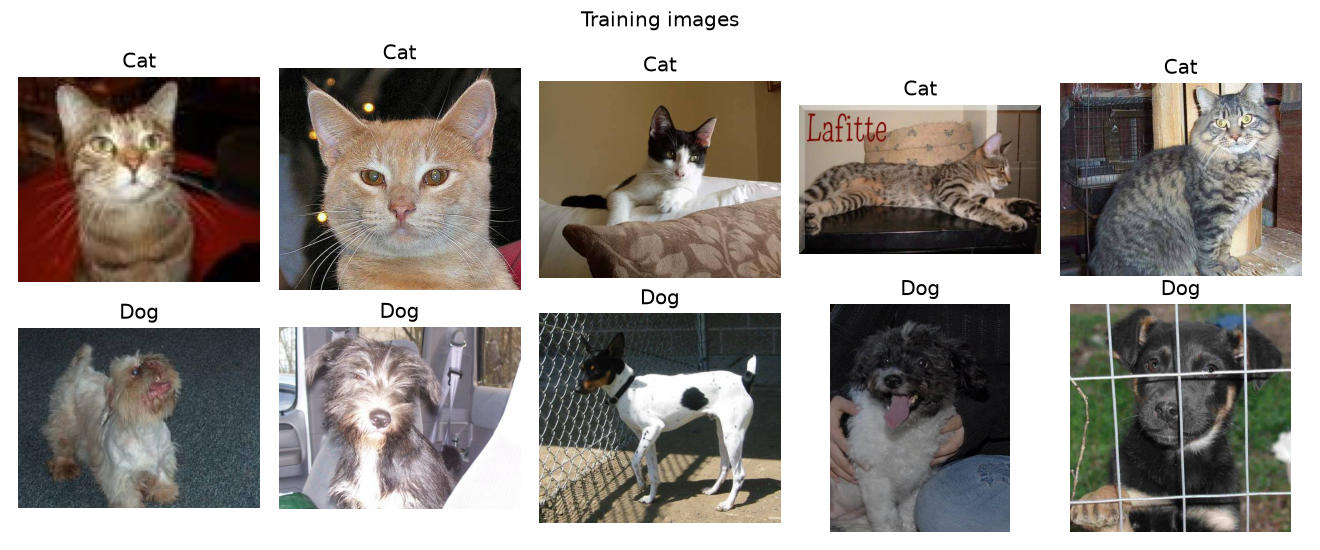

In [ ]:
URL = 'https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip'
ARCHIVE = Path('cats_and_dogs_filtered.zip')
EXPECTED_SHA256 = '91af24e0be191e9380dafc8710d0933fa826ec8e51f26f85c1fddba4e8018e3f'
if not ARCHIVE.exists():
    print('Downloading public images...')
    temporary = ARCHIVE.with_suffix('.download')
    urllib.request.urlretrieve(URL, temporary)
    temporary.replace(ARCHIVE)
assert hashlib.sha256(ARCHIVE.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Archive checksum mismatch.'
archive = zipfile.ZipFile(ARCHIVE)
rows, seen, duplicates = [], set(), 0
for name in sorted(archive.namelist()):
    parts = name.split('/')
    if len(parts) != 4 or not name.lower().endswith('.jpg') or parts[1] not in ['train', 'validation']:
        continue
    content = archive.read(name)
    digest = hashlib.sha256(content).hexdigest()
    if digest in seen:
        duplicates += 1
        continue
    seen.add(digest)
    assert parts[2] in ['cats', 'dogs']
    rows.append({'filename': name, 'split': 'development' if parts[1] == 'train' else 'test',
                 'target': int(parts[2] == 'dogs')})
metadata = pd.DataFrame(rows)
dev_idx = np.flatnonzero(metadata.split == 'development')
test_idx = np.flatnonzero(metadata.split == 'test')
fit_idx, val_idx = train_test_split(dev_idx, test_size=0.2, random_state=SEED,
                                   stratify=metadata.loc[dev_idx, 'target'])
y = metadata.target.to_numpy()
assert set(dev_idx).isdisjoint(test_idx)
print('Exact duplicate files removed:', duplicates)
display(pd.crosstab(metadata.split, metadata.target).rename(columns={0: 'Cat', 1: 'Dog'}))

def read_rgb(filename_or_bytes):
    content = archive.read(filename_or_bytes) if isinstance(filename_or_bytes, str) else filename_or_bytes
    with Image.open(io.BytesIO(content)) as image:
        return ImageOps.exif_transpose(image).convert('RGB').copy()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
rng = np.random.default_rng(SEED)
for label, row_axes in enumerate(axes):
    choices = rng.choice(fit_idx[y[fit_idx] == label], size=5, replace=False)
    for ax, index in zip(row_axes, choices):
        ax.imshow(read_rgb(metadata.loc[index, 'filename']))
        ax.set_title(['Cat', 'Dog'][label]); ax.axis('off')
fig.suptitle('Training images')
fig.tight_layout()
plt.show()

## 2. 取り出す特徴 / Hand-designed features

画像を128×128にリサイズし、以下を計算します。画像全体を縦横それぞれ縮小するため、元の縦横比は保持しません。動物の切り抜きは行わず、背景も含めます。
Resize each full image to 128×128. This changes the aspect ratio when necessary. We do not crop or segment the animal, so background information is included.

| 特徴 / Feature | 内容 / Meaning | 次元 / Dimensions |
|---|---|---:|
| Color | HSV各成分の16区間ヒストグラム / 16-bin histogram for each HSV channel | 48 |
| HOG | 小領域ごとの明るさの変化の向き / Local distributions of gradient orientations | 1764 |
| Texture | LBPによる近傍画素の明暗パターンのヒストグラム / Histogram of local binary patterns | 10 |
| Combined | 上記を連結 / Concatenation of the above | 1822 |

HOGは「耳」や「目」を直接表す特徴ではありません。明るさがどの向きに変わるかを集計したものです。色だけでは位置や形を失い、LBPの全体ヒストグラムも位置を保持しません。
HOG does not directly encode ears or eyes; it summarizes gradient directions. Color histograms lose spatial shape information, and the global LBP histogram also discards location.

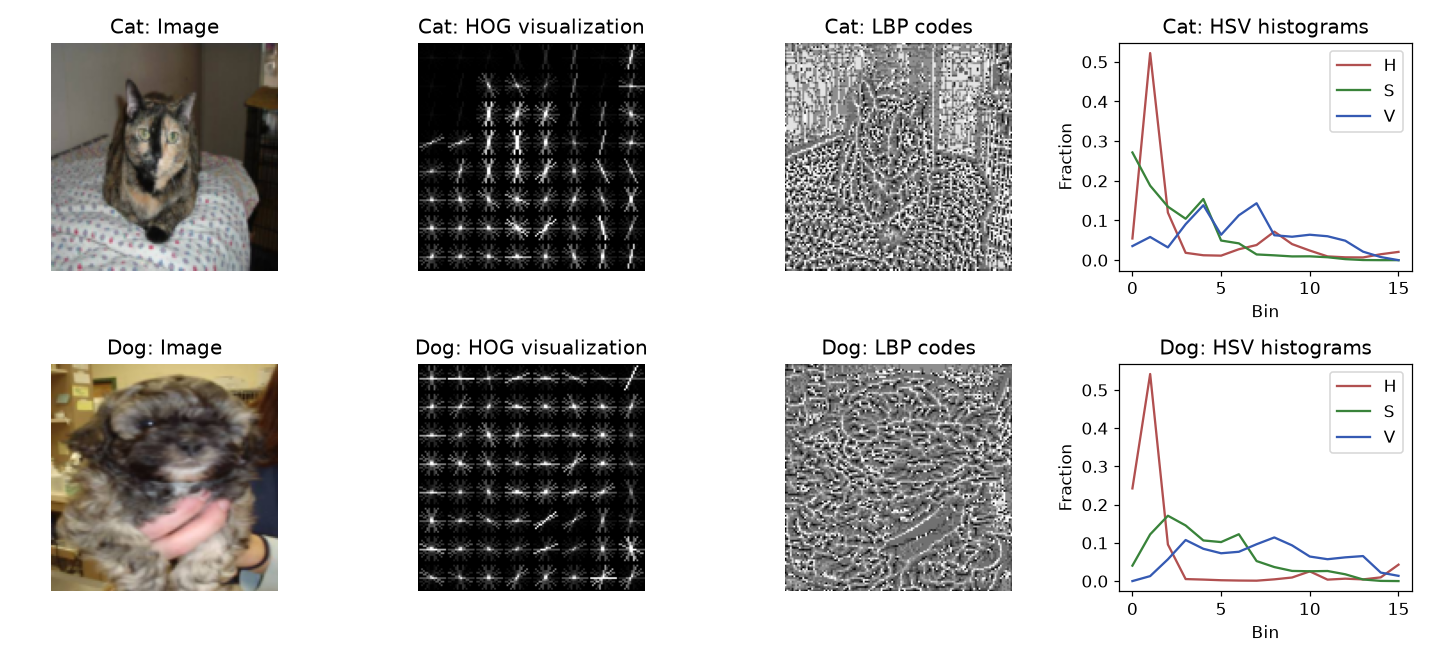

In [ ]:
SIZE = (128, 128)
def extract_features(image, visualize=False):
    rgb = np.asarray(image.resize(SIZE, Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    gray = rgb2gray(rgb)
    hsv = rgb2hsv(rgb)
    # 各ヒストグラムを合計1に正規化 / Normalize each histogram to sum to one.
    color = np.concatenate([np.histogram(hsv[:, :, channel], bins=16, range=(0, 1))[0]
                            / hsv.shape[0] / hsv.shape[1] for channel in range(3)])
    hog_result = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                     block_norm='L2-Hys', transform_sqrt=True, visualize=visualize)
    shape, hog_image = hog_result if visualize else (hog_result, None)
    # LBPは整数の輝度画像で計算 / Compute LBP on an integer grayscale image.
    lbp = local_binary_pattern(np.round(gray * 255).astype(np.uint8), P=8, R=1, method='uniform')
    texture = np.histogram(lbp, bins=np.arange(11))[0].astype(float)
    texture /= texture.sum()
    features = {'Color': color.astype(np.float32), 'HOG': shape.astype(np.float32),
                'Texture': texture.astype(np.float32)}
    features['Combined'] = np.concatenate(list(features.values()))
    if visualize:
        return features, rgb, hog_image, lbp
    return features

# 2枚で特徴の見え方を比較 / Visualize features for two training images.
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for label in [0, 1]:
    index = fit_idx[y[fit_idx] == label][0]
    features, rgb, hog_image, lbp = extract_features(read_rgb(metadata.loc[index, 'filename']), True)
    axes[label, 0].imshow(rgb)
    axes[label, 1].imshow(hog_image, cmap='gray', vmax=max(np.percentile(hog_image, 99), 1e-6))
    axes[label, 2].imshow(lbp, cmap='gray', vmin=0, vmax=9)
    for channel, color in enumerate(['#b15050', '#39833a', '#355ab3']):
        axes[label, 3].plot(np.arange(16), features['Color'][channel * 16:(channel + 1) * 16],
                            label=['H', 'S', 'V'][channel], color=color)
    for ax, title in zip(axes[label], ['Image', 'HOG visualization', 'LBP codes', 'HSV histograms']):
        ax.set_title(f'{["Cat", "Dog"][label]}: {title}')
    for ax in axes[label, :3]: ax.axis('off')
    axes[label, 3].set(xlabel='Bin', ylabel='Fraction')
    axes[label, 3].legend()
fig.tight_layout()
fig.savefig(OUT / 'feature_examples.png', dpi=160, bbox_inches='tight')
plt.show()

In [ ]:
# 画像ごとに独立して特徴を計算 / Extract each image independently, without fitting statistics.
feature_rows = {name: [] for name in ['Color', 'HOG', 'Texture', 'Combined']}
for index, filename in enumerate(metadata.filename):
    result = extract_features(read_rgb(filename))
    for name in feature_rows:
        feature_rows[name].append(result[name])
    if (index + 1) % 500 == 0:
        print(f'Processed {index + 1}/{len(metadata)} images')
X = {name: np.stack(values) for name, values in feature_rows.items()}
assert X['Combined'].shape[1] == 1822
assert all(np.isfinite(values).all() for values in X.values())
display(pd.DataFrame({'Feature set': list(X), 'Dimensions': [a.shape[1] for a in X.values()]}))

Processed 500/3000 images
Processed 1000/3000 images
Processed 1500/3000 images
Processed 2000/3000 images
Processed 2500/3000 images
Processed 3000/3000 images


,Feature set,Dimensions
0,Color,48
1,HOG,1764
2,Texture,10
3,Combined,1822


## 3. 特徴量を変えて比較 / Compare feature sets on validation data

同じ学習用・検証用画像で、色のみ、HOGのみ、模様のみ、全部の4条件を比べます。SVMは標準化を学習用だけで推定します。ここではRFは200本、SVMはRBFカーネル・C=3・gamma=scaleに固定します。
Compare color alone, HOG alone, texture alone, and their combination on identical training and validation images. SVM scaling is fitted on training images only. Random forest uses 200 trees; SVM uses an RBF kernel, C=3, and gamma=scale.

特徴量を足すほど良くなるとは限りません。高次元のHOGが、特徴数の少ない色や模様より大きな影響を持つこともあります。このデモでは組合せの重みやパラメータの探索は行いません。最終比較は事前に決めたCombinedを使用し、testで特徴量を選びません。
Adding features does not guarantee improvement. High-dimensional HOG may dominate smaller feature groups. We do not tune feature-group weights or hyperparameters here. The final comparison uses the predefined Combined features, without choosing features on test results.

,Features,Model,Accuracy,Precision,Recall,F1
0,Color,Random forest,0.6300,0.6413,0.590,0.6146
1,Color,RBF SVM,0.6125,0.6166,0.595,0.6056
2,HOG,Random forest,0.7025,0.7341,0.635,0.6810
3,HOG,RBF SVM,0.7350,0.7474,0.710,0.7282
4,Texture,Random forest,0.6375,0.6471,0.605,0.6253
5,Texture,RBF SVM,0.6275,0.6425,0.575,0.6069
6,Combined,Random forest,0.7250,0.7616,0.655,0.7043
7,Combined,RBF SVM,0.7200,0.7340,0.690,0.7113


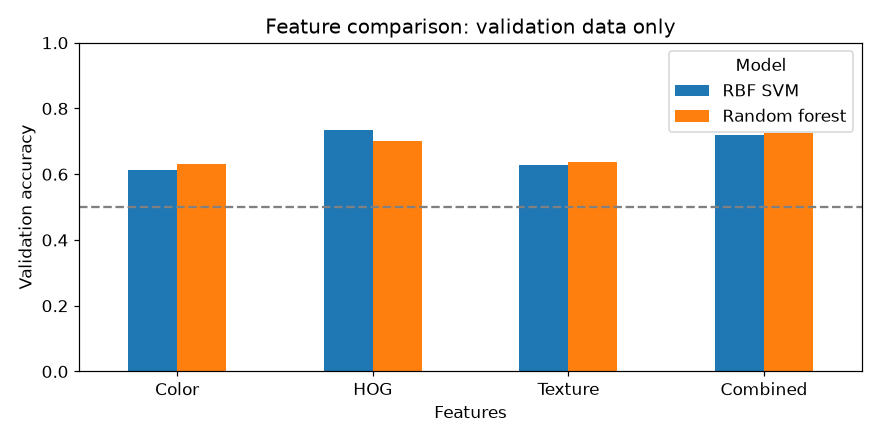

In [ ]:
templates = {
    'Random forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                           max_features='sqrt', random_state=SEED, n_jobs=-1),
    'RBF SVM': make_pipeline(StandardScaler(), SVC(C=3.0, gamma='scale', kernel='rbf')),
}
def basic_metrics(actual, predicted):
    return {'Accuracy': accuracy_score(actual, predicted),
            'Precision': precision_score(actual, predicted, zero_division=0),
            'Recall': recall_score(actual, predicted, zero_division=0),
            'F1': f1_score(actual, predicted, zero_division=0)}

comparison_rows = []
for feature_set, values in X.items():
    for name, template in templates.items():
        estimator = clone(template).fit(values[fit_idx], y[fit_idx])
        predicted = estimator.predict(values[val_idx])
        comparison_rows.append({'Features': feature_set, 'Model': name,
                                **basic_metrics(y[val_idx], predicted)})
feature_comparison = pd.DataFrame(comparison_rows)
display(feature_comparison.round(4))
feature_comparison.to_csv(OUT / 'validation_feature_comparison.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 4))
feature_comparison.pivot(index='Features', columns='Model', values='Accuracy').reindex(X.keys()).plot.bar(ax=ax)
ax.set(ylim=(0, 1), ylabel='Validation accuracy', title='Feature comparison: validation data only')
ax.axhline(0.5, color='gray', ls='--')
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(OUT / 'feature_comparison.png', dpi=160, bbox_inches='tight')
plt.show()

## 4. 交差検証 / Cross-validation

Combined特徴で、developmentだけを使う層化3分割交差検証を行います。各回でモデルと標準化を学習し直します。平均±標本標準偏差を表示します。標準偏差は信頼区間ではありません。個体IDがないため、WISDMのような個体単位の分割にはなりません。
Use stratified three-fold CV on development images with Combined features. Models and scaling are refitted within each fold. We report means ± sample standard deviations, not confidence intervals. Without animal IDs, these are image-level rather than identity-level splits.

In [ ]:
scoring = {'Accuracy': 'accuracy', 'Precision': make_scorer(precision_score, zero_division=0),
           'Recall': make_scorer(recall_score, zero_division=0),
           'F1': make_scorer(f1_score, zero_division=0)}
folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(X['Combined'][dev_idx], y[dev_idx]))
cv_rows = []
for name, template in templates.items():
    results = cross_validate(template, X['Combined'][dev_idx], y[dev_idx],
                             cv=folds, scoring=scoring, error_score='raise')
    for fold in range(3):
        cv_rows.append({'Model': name, 'Fold': fold + 1,
                        **{metric: results['test_' + metric][fold] for metric in scoring}})
cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))
cv_summary = cv_results.groupby('Model')[list(scoring)].agg(['mean', 'std'])
display(cv_summary.round(4))
cv_results.to_csv(OUT / 'cv_per_fold.csv', index=False)
cv_summary.to_csv(OUT / 'cv_mean_std.csv')

,Model,Fold,Accuracy,Precision,Recall,F1
0,Random forest,1,0.7046,0.7138,0.6817,0.6974
1,Random forest,2,0.7346,0.7774,0.6587,0.7131
2,Random forest,3,0.7027,0.7213,0.6607,0.6897
3,RBF SVM,1,0.7256,0.7389,0.6967,0.7172
4,RBF SVM,2,0.7646,0.7792,0.7395,0.7588
5,RBF SVM,3,0.7147,0.7134,0.7177,0.7156


Accuracy         Precision         Recall              F1        
                  mean     std      mean     std   mean     std    mean     std
Model                                                                          
RBF SVM          0.735  0.0262    0.7438  0.0332  0.718  0.0214  0.7305  0.0245
Random forest    0.714  0.0179    0.7375  0.0347  0.667  0.0127  0.7001  0.0120

## 5. 最終テスト / Final test evaluation

Combined特徴を使い、development全体で2モデルを学習し直します。testはここで評価します。**行＝実際、列＝予測、陽性＝Dog**です。左上TP、右上FN、左下FP、右下TNの順に表示します。
Refit both models on all development images with Combined features, then evaluate the test set. **Rows = actual; columns = predicted; positive = Dog.** Layout: TP top left, FN top right, FP bottom left, TN bottom right.

正解率=(TP+TN)/N、適合率=TP/(TP+FP)、再現率=TP/(TP+FN)、F1=2TP/(2TP+FP+FN)。分母が0の指標は実装上0とします。
Accuracy=(TP+TN)/N, precision=TP/(TP+FP), recall=TP/(TP+FN), F1=2TP/(2TP+FP+FN). Zero-denominator scores are reported as zero by convention.

SVMの決定スコアは確率ではありません。ROC-AUCとAverage Precisionには連続スコアを使えますが、スコアの大きさを確率として読まないでください。
SVM decision scores are not probabilities. Continuous scores can be used for ROC-AUC and average precision, but their magnitudes should not be read as probabilities.

               Accuracy  Precision  Recall      F1  ROC-AUC  Average precision   TP   FN   FP   TN
Model                                                                                             
Random forest     0.729     0.7562   0.676  0.7138   0.8109             0.8139  338  162  109  391
RBF SVM           0.760     0.7754   0.732  0.7531   0.8406             0.8514  366  134  106  394


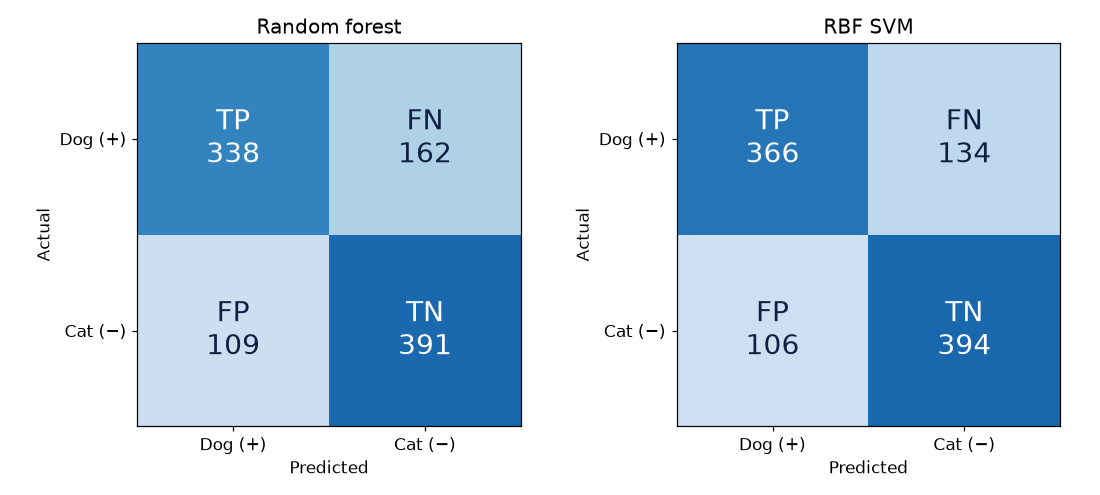

,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision,TP,FN,FP,TN
Model,,,,,,,,,,
Random forest,0.729,0.7562,0.676,0.7138,0.8109,0.8139,338,162,109,391
RBF SVM,0.760,0.7754,0.732,0.7531,0.8406,0.8514,366,134,106,394


In [ ]:
models, test_predictions, test_rows = {}, {}, []
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, template) in zip(axes, templates.items()):
    estimator = clone(template).fit(X['Combined'][dev_idx], y[dev_idx])
    models[name] = estimator
    prediction = estimator.predict(X['Combined'][test_idx])
    test_predictions[name] = prediction
    score = (estimator.decision_function(X['Combined'][test_idx]) if hasattr(estimator, 'decision_function')
             else estimator.predict_proba(X['Combined'][test_idx])[:, 1])
    cm = confusion_matrix(y[test_idx], prediction, labels=[1, 0])
    tp, fn, fp, tn = cm.ravel()
    assert cm.sum() == len(test_idx)
    test_rows.append({'Model': name, **basic_metrics(y[test_idx], prediction),
                     'ROC-AUC': roc_auc_score(y[test_idx], score),
                     'Average precision': average_precision_score(y[test_idx], score),
                     'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn})
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=len(test_idx) / 2)
    for row in range(2):
        for col in range(2):
            term = [['TP', 'FN'], ['FP', 'TN']][row][col]
            ax.text(col, row, f'{term}\n{cm[row, col]}', ha='center', va='center', fontsize=18,
                    color='white' if cm[row, col] > len(test_idx) / 4 else '#102044')
    ax.set(title=name, xticks=[0, 1], yticks=[0, 1], xticklabels=['Dog (+)', 'Cat (−)'],
           yticklabels=['Dog (+)', 'Cat (−)'], xlabel='Predicted', ylabel='Actual')
fig.tight_layout()
fig.savefig(OUT / 'test_confusion_matrices.png', dpi=160, bbox_inches='tight')
plt.show()
test_metrics = pd.DataFrame(test_rows).set_index('Model')
display(test_metrics.round(4))
print(test_metrics.round(4).to_string())
test_metrics.to_csv(OUT / 'test_metrics.csv')
predictions_table = metadata.iloc[test_idx].copy()
for name, values in test_predictions.items(): predictions_table[name] = values
predictions_table.to_csv(OUT / 'test_predictions.csv', index=False)

## 6. 間違えた画像を見る / Inspect errors

各モデルの誤判定画像を固定した乱数で最大6枚表示します。背景、姿勢、被写体の大きさなどに注目してください。ただし見た目だけで、モデルが間違えた原因を断定することはできません。
Show up to six randomly selected errors per model with a fixed seed. Inspect background, pose, and subject size. Visual inspection alone does not establish the causal reason for an error.

testの誤りを参考に特徴や設定を変えた場合、同じtestは独立した最終評価ではなくなります。変更後の最終確認には別の未使用データを用意してください。
If you revise features or settings based on test errors, this set is no longer an independent final evaluation. Use new unused data for final assessment after such revisions.

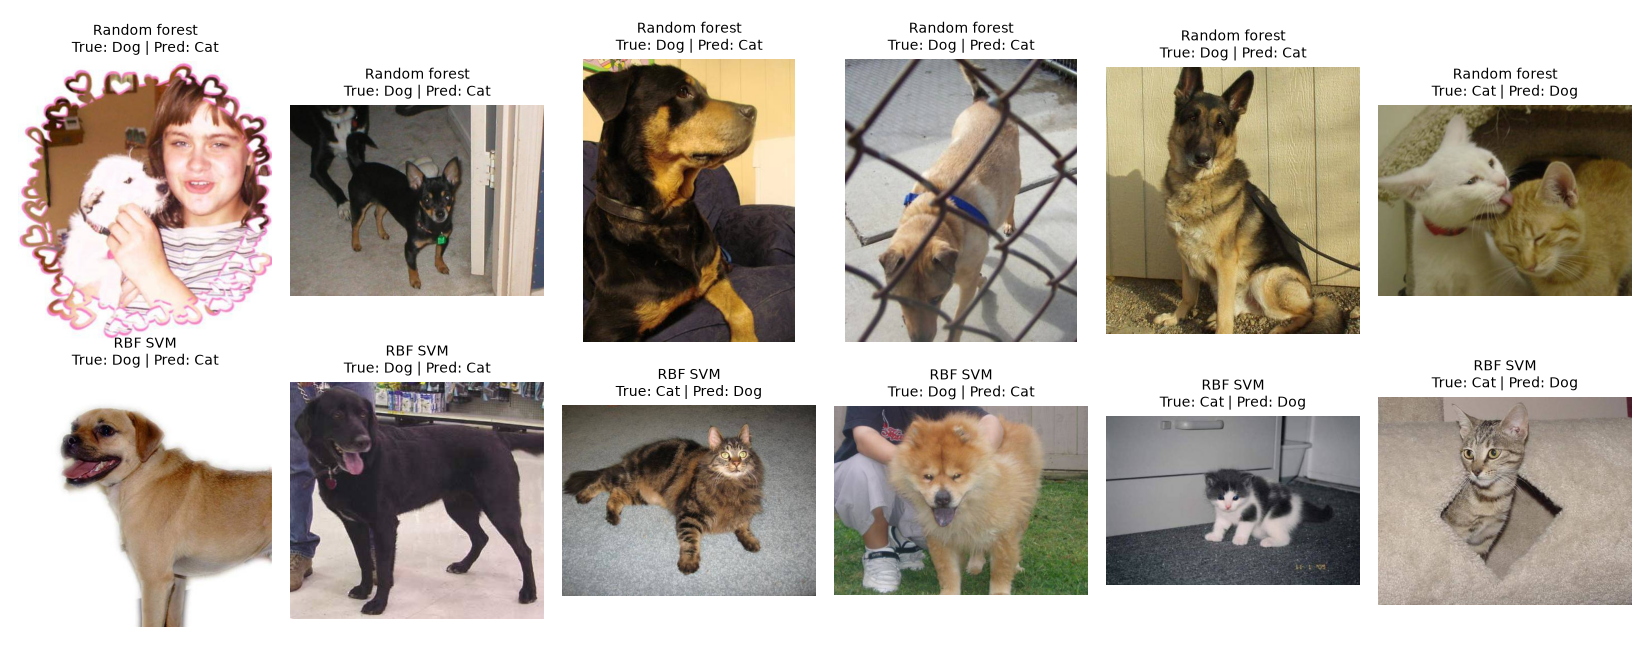

In [ ]:
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for row, (name, prediction) in enumerate(test_predictions.items()):
    wrong = np.flatnonzero(prediction != y[test_idx])
    selected = np.random.default_rng(SEED).choice(wrong, size=min(6, len(wrong)), replace=False)
    for ax in axes[row]: ax.axis('off')
    for ax, position in zip(axes[row], selected):
        index = test_idx[position]
        ax.imshow(read_rgb(metadata.loc[index, 'filename']))
        actual, predicted = ['Cat', 'Dog'][y[index]], ['Cat', 'Dog'][prediction[position]]
        ax.set_title(f'{name}\nTrue: {actual} | Pred: {predicted}', fontsize=9)
fig.tight_layout()
fig.savefig(OUT / 'test_errors.png', dpi=140, bbox_inches='tight')
plt.show()

## 7. 自分の犬・猫画像を試す（任意） / Try your own image (optional)

下のチェックを有効にしてセルを実行すると、Colabで画像を選べます。同じ前処理と特徴量で判定します。犬猫以外でも必ずどちらかを出す二択モデルであり、「犬猫以外」を検出する機能はありません。
Enable the checkbox and run the cell to upload an image in Colab. The same preprocessing and features are used. This binary classifier always chooses cat or dog and does not detect other categories.

In [ ]:
# @title 画像をアップロード / Upload an image
upload_my_image = False # @param {type:"boolean"}
if upload_my_image:
    from google.colab import files
    uploaded = files.upload()
    for filename, content in uploaded.items():
        picture = read_rgb(content)
        vector = extract_features(picture)['Combined'][None, :]
        predictions = {name: ['Cat', 'Dog'][int(model.predict(vector)[0])] for name, model in models.items()}
        display(pd.Series(predictions, name=filename).to_frame())
        plt.figure(figsize=(4, 4))
        plt.imshow(picture); plt.axis('off'); plt.title(filename); plt.show()
else:
    print('Optional upload skipped.')

Optional upload skipped.


## まとめ / Takeaways

- 分類器に渡す前に、画像から数値特徴を作りました。 / Images were converted to numeric features before classification.
- 特徴量の選択と、分類器の選択は別の問題です。 / Feature selection and classifier selection are separate choices.
- 色・輪郭・模様だけで難しい例は、「特徴そのものを学習する」ニューラルネットワークの動機にもなります。 / Difficult cases motivate learning representations with neural networks.
- 数値の比較と誤りの観察を組み合わせて考えましょう。 / Combine quantitative evaluation with inspection of errors.

画像とCSVは `cats_dogs_outputs` に保存されます。
Figures and CSV files are saved in `cats_dogs_outputs`.